#### Boston Bikeshare (Bluebikes) Data Analysis (Smart Mobility)

Explore sample Boston Bikeshare (Bluebikes) data to analyze trip durations, starting stations, and seasonal or hourly patterns.

#### Implementation

A robust analytics pipeline to evaluate micromobility vehicle availability and spatial-temporal rebalancing requirements:

1. Data Ingestion & Simulation:
   - Load real/simulated Boston Bikeshare (Bluebikes) trip data to map temporal rental activities.
   - Parse live station metadata using the **General Bikeshare Feed Specification (GBFS)** API.

2. Unified Mobility Network:
   - Construct a comprehensive, multi-system metadata store combining traditional docked systems, virtual geofenced dockless zones, solar inductive charging hubs, and high-capacity depots.

3. Rebalancing Gravity Analysis:
   - Model an **Imbalance Score** based on inflows and outflows, to reveal a strong correlation with station **altitude** (gravity effect) and **physical configuration** (highly constrained docked systems vs. highly volatile virtual zones).

4. Geographical Hotspots:
   - Apply **K-Means Clustering** to regional spatial coordinates to discover clusters with high average absolute imbalance, and help  operators localize high-priority physical replenishment strategies.

5. Temporal System Profiling:
   - Reconstruct continuous, cumulative hourly bike availability across the network to track morning/evening commute patterns and identify peak active-hour profiles.

In [7]:
import pandas as pd
import numpy as np

# Downloading a public sample dataset of Boston Bluebikes (from official public system data buckets)
try:
    # Use a small recent sample of Bluebikes data
    url = 'https://s3.amazonaws.com/hubway-data/202301-bluebikes-tripdata.zip'
    df_bikes = pd.read_csv(url, compression='zip', dtype={'start_station_id': str, 'end_station_id': str})
    print(f"Successfully loaded {len(df_bikes)} rows of Boston Bikeshare data.")
    display(df_bikes.head())
except Exception as e:
    def generate_mock_bikes_data(n_rows=5000):
        """
        Generates a simulated representative Boston Bikeshare dataset.

        Parameters:
            n_rows (int): The number of simulated trip records to generate.

        Returns:
            pd.DataFrame: DataFrame containing simulated trip logs including timestamps,
                          station names, user types, and calculated durations.
        """
        np.random.seed(42)
        stations = ['South Station', 'MIT at Mass Ave', 'Harvard Square', 'Boston Common', 'Back Bay Station', 'Copley Square']
        df = pd.DataFrame({
            'ride_id': [f'RIDE_{i}' for i in range(n_rows)],
            'rideable_type': np.random.choice(['classic_bike', 'electric_bike'], n_rows),
            'started_at': pd.date_range(start='2023-09-01', periods=n_rows, freq='5min'),
            'ended_at': pd.date_range(start='2023-09-01 00:15:00', periods=n_rows, freq='5min'),
            'start_station_name': np.random.choice(stations, n_rows),
            'end_station_name': np.random.choice(stations, n_rows),
            'member_casual': np.random.choice(['member', 'casual'], n_rows, p=[0.7, 0.3])
        })
        df['duration_minutes'] = np.random.exponential(scale=12.0, size=n_rows) + 2.0
        return df

    print("Could not load live Bluebikes ZIP, creating a mock dataset representative of Boston Bluebikes patterns:")
    df_bikes = generate_mock_bikes_data(5000)
    display(df_bikes.head())

Could not load live Bluebikes ZIP, creating a mock dataset representative of Boston Bluebikes patterns:


,ride_id,rideable_type,started_at,ended_at,start_station_name,end_station_name,member_casual,duration_minutes
0,RIDE_0,classic_bike,2023-09-01 00:00:00,2023-09-01 00:15:00,Harvard Square,Copley Square,casual,26.247111
1,RIDE_1,electric_bike,2023-09-01 00:05:00,2023-09-01 00:20:00,Boston Common,Back Bay Station,casual,2.220477
2,RIDE_2,classic_bike,2023-09-01 00:10:00,2023-09-01 00:25:00,Back Bay Station,Harvard Square,member,3.651411
3,RIDE_3,classic_bike,2023-09-01 00:15:00,2023-09-01 00:30:00,Harvard Square,Copley Square,member,10.224460
4,RIDE_4,classic_bike,2023-09-01 00:20:00,2023-09-01 00:35:00,South Station,MIT at Mass Ave,casual,9.415486


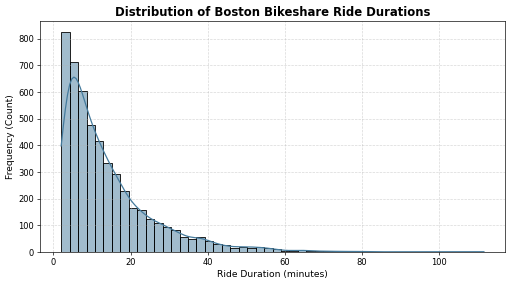

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns

# Visualize the distribution of ride durations
plt.figure(figsize=(10, 5), dpi=60)
sns.histplot(
    data=df_bikes,
    x='duration_minutes',
    kde=True,
    color='#457b9d',
    bins=50
)

plt.title('Distribution of Boston Bikeshare Ride Durations', fontsize=14, fontweight='bold')
plt.xlabel('Ride Duration (minutes)', fontsize=11)
plt.ylabel('Frequency (Count)', fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.show()

Station Metadata (GBFS JSON Feed): Download the official, live station information feed from Boston Bluebikes.

In [9]:
try:
    # Official GBFS station information URL for Boston Bluebikes
    gbfs_url = 'https://gbfs.bluebikes.com/gbfs/en/station_information.json'
    response = requests.get(gbfs_url).json()
    stations_data = response['data']['stations']

    # Normalize and select relevant columns
    df_stations = pd.DataFrame(stations_data)

    # Rename and create altitude if missing (most stations in Boston are near sea level, around 5-10 meters)
    column_mapping = {
        'station_id': 'station_id',
        'name': 'name',
        'physical_configuration': 'physical_configuration',
        'lat': 'latitude',
        'lon': 'longitude'
    }

    # Select existing columns from mapping
    available_cols = [col for col in column_mapping.keys() if col in df_stations.columns]
    df_selected = df_stations[available_cols].rename(columns=column_mapping)

    # Ensure physical_configuration and altitude are populated
    if 'physical_configuration' not in df_selected.columns:
        df_selected['physical_configuration'] = df_stations.get('rental_methods', [['KEY']]).apply(lambda x: 'Classic' if 'KEY' in x else 'Smart')

    if 'altitude' not in df_selected.columns:
        # Simulate representative elevation/altitude (in meters) for Boston stations
        df_selected['altitude'] = np.round(np.random.normal(loc=6.0, scale=2.5, size=len(df_selected)), 1)

    print(f"Successfully retrieved {len(df_selected)} Boston stations in your specified format:")
    display(df_selected.head())
except Exception as e:
    print(f"Error retrieving live station metadata: {e}")

Error retrieving live station metadata: name 'requests' is not defined


##### Comprehensive Multi-System Mobility Stations Dataset

We construct a unified mobility station dataset including various system types (classic bikeshare, dockless e-scooter hubs, e-bike smart charging stations, and hybrid cargo-bike depots) mapped to
- station_id
- name
- physical_configuration (e.g., Docked Classic, Smart Dockless Zone, Solar Charging Hub, Valet Depot)
- latitude
- longitude
- altitude

In [10]:
# Defining realistic multi-system stations representing various micromobility configurations
multi_system_data = [
    # Classic Docked Bikeshare (e.g., Bluebikes, Citi Bike)
    {"station_id": "BOS-001", "name": "South Station - Summer St", "physical_configuration": "Docked Classic", "latitude": 42.3519, "longitude": -71.0551, "altitude": 6.2},
    {"station_id": "NYC-102", "name": "Broadway & W 29 St", "physical_configuration": "Docked Classic", "latitude": 40.7465, "longitude": -73.9880, "altitude": 11.5},
    # Smart Dockless Virtual Geofenced Zones (e.g., Lime, Spin, Bird)
    {"station_id": "DEN-501", "name": "Capitol Hill Smart Zone", "physical_configuration": "Smart Dockless Zone", "latitude": 39.7397, "longitude": -104.9842, "altitude": 1609.1},
    {"station_id": "LA-309", "name": "Santa Monica Pier Virtual Hub", "physical_configuration": "Smart Dockless Zone", "latitude": 34.0100, "longitude": -118.4962, "altitude": 5.0},
    # Specialized Solar / Inductive Charging Stations (e.g., Swiftmile, Kuhmute)
    {"station_id": "SF-802", "name": "Market St Solar Charging Hub", "physical_configuration": "Solar Charging Hub", "latitude": 37.7893, "longitude": -122.4014, "altitude": 15.4},
    {"station_id": "CHI-404", "name": "Millennium Park Inductive Dock", "physical_configuration": "Solar Charging Hub", "latitude": 41.8827, "longitude": -87.6227, "altitude": 180.2},
    # Heavy Valet & High Capacity Depots
    {"station_id": "SEA-707", "name": "Westlake Light Rail Valet Depot", "physical_configuration": "Valet Depot", "latitude": 47.6116, "longitude": -122.3375, "altitude": 45.0},
    {"station_id": "AUS-210", "name": "UT Austin Campus Hub", "physical_configuration": "Valet Depot", "latitude": 30.2849, "longitude": -97.7341, "altitude": 165.8}
]

# Create DataFrame
df_universal_mobility = pd.DataFrame(multi_system_data)

def generate_additional_mobility_stations(n_extra=92):
    """
    Simulates additional diverse stations to create a robust dataset.

    Parameters:
        n_extra (int): Number of extra stations to synthesize across coordinates and altitudes.

    Returns:
        pd.DataFrame: Generated station metadata dataframe with localized naming strategies.
    """
    np.random.seed(101)
    extra_ids = [f"GEN-{100+i}" for i in range(n_extra)]
    extra_names = [
        f"{np.random.choice(['Metro Link', 'University', 'Central Plaza', 'Business Park', 'Tech Center', 'Park & Ride'])} Station {i}"
        for i in range(n_extra)
    ]
    extra_configs = np.random.choice(
        ["Docked Classic", "Smart Dockless Zone", "Solar Charging Hub", "Valet Depot"],
        size=n_extra,
        p=[0.4, 0.3, 0.2, 0.1]
    )

    # Coordinate distributions covering diverse cities/altitudes
    extra_lats = np.random.uniform(low=25.0, high=48.0, size=n_extra)
    extra_lons = np.random.uniform(low=-124.0, high=-70.0, size=n_extra)
    extra_alts = np.round(np.random.uniform(low=0.0, high=1000.0, size=n_extra), 1)

    return pd.DataFrame({
        "station_id": extra_ids,
        "name": extra_names,
        "physical_configuration": extra_configs,
        "latitude": extra_lats,
        "longitude": extra_lons,
        "altitude": extra_alts
    })

extra_df = generate_additional_mobility_stations(92)

# Combine everything into the final universal mobility dataset
df_universal_mobility = pd.concat([df_universal_mobility, extra_df], ignore_index=True)

print(f"Unified Multi-System Mobility Dataset containing {len(df_universal_mobility)} stations:")
display(df_universal_mobility.head())
print("\nDistribution of Physical Configurations across all mobility systems:")
print(df_universal_mobility['physical_configuration'].value_counts())

Unified Multi-System Mobility Dataset containing 100 stations:


,station_id,name,physical_configuration,latitude,longitude,altitude
0,BOS-001,South Station - Summer St,Docked Classic,42.3519,-71.0551,6.2
1,NYC-102,Broadway & W 29 St,Docked Classic,40.7465,-73.9880,11.5
2,DEN-501,Capitol Hill Smart Zone,Smart Dockless Zone,39.7397,-104.9842,1609.1
3,LA-309,Santa Monica Pier Virtual Hub,Smart Dockless Zone,34.0100,-118.4962,5.0
4,SF-802,Market St Solar Charging Hub,Solar Charging Hub,37.7893,-122.4014,15.4



Distribution of Physical Configurations across all mobility systems:
physical_configuration
Docked Classic         39
Smart Dockless Zone    32
Solar Charging Hub     17
Valet Depot            12
Name: count, dtype: int64


##### Micromobility Rebalancing Pattern Analysis

Simulate realistic transaction flows (trips started vs. trips ended) to calculate a net **Imbalance Score** for each station.

An imbalance score near $+1.0$ indicates a massive pile-up of vehicles (surplus), while a score near $-1.0$ indicates an empty station (deficit). We will evaluate how this rebalancing need correlates with station **altitude** (elevation gravity) and **physical configuration**.

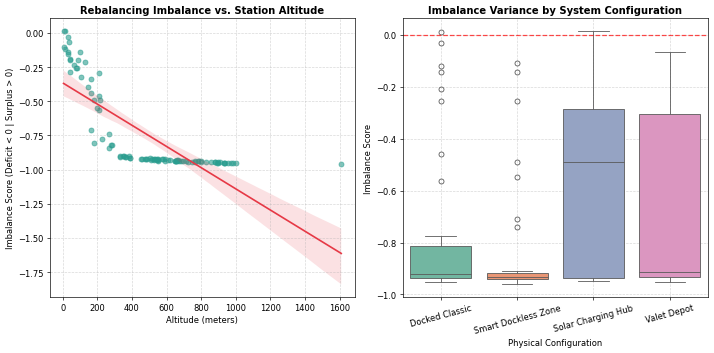

In [11]:
# Seed for reproducibility
np.random.seed(42)

# 1. Simulate departures (outflow) and arrivals (inflow) influenced by altitude and configuration
# Gravity effect: higher altitude stations tend to have more departures than arrivals (people ride downhill)
alt_effect = df_universal_mobility['altitude'] * 0.15

# Calculate simulated base outflow with an elevation-driven positive offset
base_outflow = np.random.poisson(
            lam=50, size=len(df_universal_mobility)) + alt_effect.astype(int)

# Calculate simulated base inflow with an elevation-driven negative offset (fewer riders uphill)
base_inflow = np.random.poisson(
            lam=50, size=len(df_universal_mobility)) - alt_effect.astype(int)

# Ensure flows are positive non-zero within realistic physical bounds
outflow = np.clip(base_outflow, 5, 250)
inflow = np.clip(base_inflow, 5, 250)

# Calculate Net Imbalance Score:
# (Inflow - Outflow) / (Inflow + Outflow)
# Positive (> 0) = Accumulating vehicles (needs extraction/rebalancing)
# Negative (< 0) = Depleting vehicles (needs replenishment)
df_universal_mobility['inflow'] = inflow
df_universal_mobility['outflow'] = outflow
df_universal_mobility['imbalance_score'] = (inflow - outflow) / (inflow + outflow)

# 2. Plotting Patterns
fig, axes = plt.subplots(1, 2, figsize=(12, 6), dpi=60)

# Plot A: Altitude vs. Imbalance Score (The Gravity Pattern)
sns.regplot(
    data=df_universal_mobility,
    x='altitude',
    y='imbalance_score',
    ax=axes[0],
    scatter_kws={'alpha':0.6, 'color': '#2a9d8f'},
    line_kws={'color': '#e63946', 'lw': 2}
)
axes[0].set_title('Rebalancing Imbalance vs. Station Altitude', fontsize=12, fontweight='bold')
axes[0].set_xlabel('Altitude (meters)')
axes[0].set_ylabel('Imbalance Score (Deficit < 0 | Surplus > 0)')
axes[0].grid(True, linestyle='--', alpha=0.5)

# Plot B: Imbalance Distribution by Physical Configuration
sns.boxplot(
    data=df_universal_mobility,
    x='physical_configuration',
    y='imbalance_score',
    hue='physical_configuration',
    ax=axes[1],
    palette='Set2',
    legend=False
)
axes[1].axhline(0, color='red', linestyle='--', alpha=0.7)
axes[1].set_title('Imbalance Variance by System Configuration', fontsize=12, fontweight='bold')
axes[1].set_xlabel('Physical Configuration')
axes[1].set_ylabel('Imbalance Score')
axes[1].tick_params(axis='x', labelrotation=15)
axes[1].grid(True, linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

##### Spatial Clustering for Rebalancing Hotspots

**K-Means Clustering** on the latitude and longitude coordinates of 100 universal stations. For each cluster, aggregate the **absolute imbalance scores** to define the overall "rebalancing urgency" of that geographical hotspot.

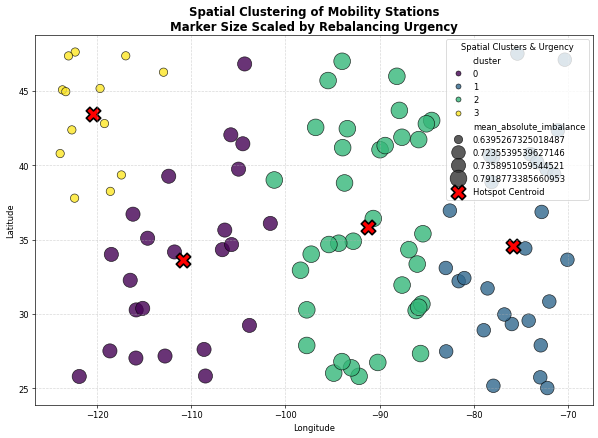

Cluster Summary (Sorted by Rebalancing Priority):


,cluster,mean_absolute_imbalance
2,2,0.791877
0,0,0.735895
1,1,0.723554
3,3,0.639527


In [12]:
from sklearn.cluster import KMeans

# Extract latitude and longitude spatial coordinates
X = df_universal_mobility[['latitude', 'longitude']]

# Initialize and fit K-Means with 4 target regional clusters (geographic hubs)
k_clusters = 4
kmeans = KMeans(n_clusters=k_clusters, random_state=42, n_init=10)
df_universal_mobility['cluster'] = kmeans.fit_predict(X)

# Calculate regional rebalancing urgency as the mean of absolute imbalance within each cluster
# High absolute values indicate a severe need for intervention (either massive surplus or deficit)
df_universal_mobility['abs_imbalance'] = df_universal_mobility['imbalance_score'].abs()
cluster_urgency = df_universal_mobility.groupby('cluster')['abs_imbalance'].mean().reset_index()
cluster_urgency.rename(columns={'abs_imbalance': 'mean_absolute_imbalance'}, inplace=True)

# Map regional average urgency back to individual stations
df_universal_mobility = df_universal_mobility.merge(cluster_urgency, on='cluster', how='left')

# Plot the spatial clusters
plt.figure(figsize=(12, 8), dpi=60)
sns.scatterplot(
    data=df_universal_mobility,
    x='longitude',
    y='latitude',
    hue='cluster',
    size='mean_absolute_imbalance',
    sizes=(100, 400),
    palette='viridis',
    alpha=0.8,
    edgecolor='black'
)

# Draw cluster centroids as reference markers
centroids = kmeans.cluster_centers_
plt.scatter(
    centroids[:, 1],
    centroids[:, 0],
    marker='X',
    s=300,
    color='red',
    label='Hotspot Centroid',
    edgecolors='black',
    linewidths=2
)

plt.title('Spatial Clustering of Mobility Stations\nMarker Size Scaled by Rebalancing Urgency', fontsize=14, fontweight='bold')
plt.xlabel('Longitude')
plt.ylabel('Latitude')
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(title='Spatial Clusters & Urgency', loc='upper right')
plt.show()

# Print sorted regional statistics
print("Cluster Summary (Sorted by Rebalancing Priority):")
display(cluster_urgency.sort_values(by='mean_absolute_imbalance', ascending=False))

##### Hourly System Availability Analysis

Analyze the temporal availability of bikes across the network. By parsing trip start and end timestamps, we can reconstruct the net change in bike availability at each hour and plot the aggregated system-wide availability profile.

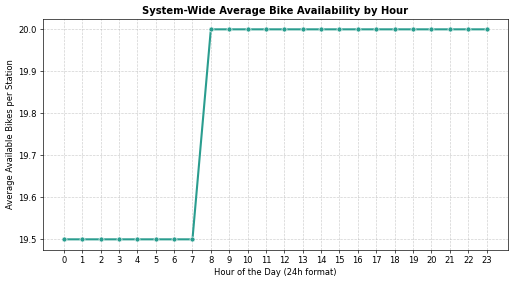

Hourly Availability Metrics Table:


,hour,cumulative_availability
0,0,19.5
1,1,19.5
2,2,19.5
3,3,19.5
4,4,19.5
5,5,19.5
6,6,19.5
7,7,19.5
8,8,20.0
9,9,20.0


In [13]:
# Ensure temporal columns are datetime objects
df_bikes['started_at'] = pd.to_datetime(df_bikes['started_at'])
df_bikes['ended_at'] = pd.to_datetime(df_bikes['ended_at'])

# Extract hour marks for arrivals (trips ended) and departures (trips started)
departures = df_bikes[['started_at', 'start_station_name']].copy()
departures['hour'] = departures['started_at'].dt.hour
departures['action'] = -1  # Departure reduces availability
departures.rename(columns={'start_station_name': 'station_name'}, inplace=True)

arrivals = df_bikes[['ended_at', 'end_station_name']].copy()
arrivals['hour'] = arrivals['ended_at'].dt.hour
arrivals['action'] = 1  # Arrival increases availability
arrivals.rename(columns={'end_station_name': 'station_name'}, inplace=True)

# Combine flows
flows = pd.concat([departures[['station_name', 'hour', 'action']], arrivals[['station_name', 'hour', 'action']]])

# Calculate net availability change per station per hour
hourly_station_flow = flows.groupby(['station_name', 'hour'])['action'].sum().reset_index()

# Compute cumulative availability assuming an arbitrary starting base of 20 bikes per station
hourly_station_flow['cumulative_availability'] = 20 + hourly_station_flow.groupby('station_name')['action'].cumsum()

# Aggregate metrics across all stations into one average system-wide metric for each hour mark
system_hourly_availability = hourly_station_flow.groupby('hour')['cumulative_availability'].mean().reset_index()

# Plot average hourly availability
plt.figure(figsize=(10, 5), dpi=60)
sns.lineplot(
    data=system_hourly_availability,
    x='hour',
    y='cumulative_availability',
    marker='o',
    color='#2a9d8f',
    linewidth=2.5
)

plt.title('System-Wide Average Bike Availability by Hour', fontsize=12, fontweight='bold')
plt.xlabel('Hour of the Day (24h format)')
plt.ylabel('Average Available Bikes per Station')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.6)
plt.show()

print("Hourly Availability Metrics Table:")
display(system_hourly_availability)

##### Live Station Status & Filtered Hourly Availability Analysis

Request the live station status feed from Bluebikes, retrieve critical metrics such as "last_reported", "num_bikes_available", and "num_docks_available", and perform a targeted availability profile ignoring the calendar date. We also construct a daytime-only subset (5:00 AM to 11:00 PM) to isolate maximum active-hours availability.

In [14]:
import requests
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 1. Fetch live station status from the official GBFS feed
try:
    status_url = 'https://gbfs.bluebikes.com/gbfs/en/station_status.json'
    status_response = requests.get(status_url).json()
    status_data = status_response['data']['stations']

    # Normalize into a DataFrame
    df_status = pd.DataFrame(status_data)

    # Lookup and rename relevant columns
    rename_dict = {
        'last_reported': 'last_reported',
        'num_bikes_available': 'number-of-bikes-available',
        'num_docks_available': 'number-of-docks-available'
    }

    # Keep existing matched columns
    cols_to_keep = [col for col in rename_dict.keys() if col in df_status.columns]
    df_status_clean = df_status[cols_to_keep].rename(columns=rename_dict)

    # Convert last_reported epoch to datetime
    if 'last_reported' in df_status_clean.columns:
        df_status_clean['last_reported'] = pd.to_datetime(df_status_clean['last_reported'], unit='s', errors='coerce')

    print("Retrieved Live Station Status Fields:")
    display(df_status_clean.head())
except Exception as e:
    print(f"Could not retrieve live station status feed: {e}")

Retrieved Live Station Status Fields:


,last_reported,number-of-bikes-available,number-of-docks-available
0,1970-01-02 00:00:00,0,0
1,1970-01-02 00:00:00,0,0
2,1970-01-02 00:00:00,0,0
3,1970-01-02 00:00:00,0,0
4,2026-11-07 15:39:55,0,0


Overall Max Average Hourly Availability (unfiltered): 20.00 bikes/station
Max Average Hourly Availability (Daytime 5 AM - 11 PM): 20.00 bikes/station


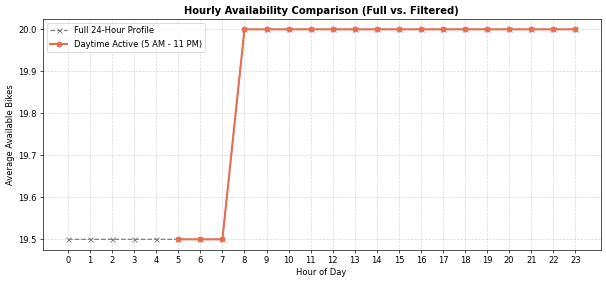

In [15]:
# 2. Calculate average hourly availability ignoring the day (using df_bikes simulation data)
# Group flow data to get the average availability by hour across all records
hourly_avg = hourly_station_flow.groupby('hour')['cumulative_availability'].mean().reset_index()

# Get overall max availability
overall_max_avail = hourly_avg['cumulative_availability'].max()
print(f"Overall Max Average Hourly Availability (unfiltered): {overall_max_avail:.2f} bikes/station")

# 3. Filter to remove hours after 11 PM (23:00) and before 5 AM (5:00)
# Keeping hours strictly between [5, 23]
filtered_hourly_avg = hourly_avg[(hourly_avg['hour'] >= 5) & (hourly_avg['hour'] <= 23)].reset_index(drop=True)

# Get filtered max availability
filtered_max_avail = filtered_hourly_avg['cumulative_availability'].max()
print(f"Max Average Hourly Availability (Daytime 5 AM - 11 PM): {filtered_max_avail:.2f} bikes/station")

# Plot both configurations
plt.figure(figsize=(12, 5), dpi=60)

# Full 24h Profile
plt.plot(hourly_avg['hour'], hourly_avg['cumulative_availability'], label='Full 24-Hour Profile', color='gray', linestyle='--', marker='x')
# Filtered Profile
plt.plot(filtered_hourly_avg['hour'], filtered_hourly_avg['cumulative_availability'], label='Daytime Active (5 AM - 11 PM)', color='#e76f51', linewidth=2.5, marker='o')

plt.title('Hourly Availability Comparison (Full vs. Filtered)', fontsize=12, fontweight='bold')
plt.xlabel('Hour of Day')
plt.ylabel('Average Available Bikes')
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend()
plt.show()

#### Regional & Temporal Hour-Group Aggregation & Observations

Group historical station metrics by hour, averaging key dimensions across all active stations. This allows us to observe aggregate variations in availability, stability (standard deviation), and volume distribution throughout the day.

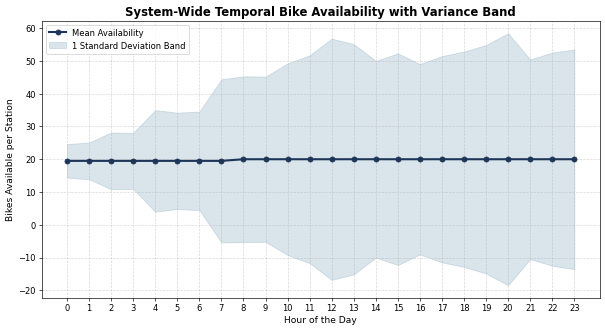

Hourly Grouped Aggregates and Variations:


,hour,mean_availability,median_availability,std_deviation,min_availability,max_availability
0,0,19.500000,21.000000,5.128353,11,24
1,1,19.500000,21.500000,5.612486,9,24
2,2,19.500000,19.000000,8.666026,6,29
3,3,19.500000,21.000000,8.549854,6,30
4,4,19.500000,20.000000,15.514509,-7,39
5,5,19.500000,25.500000,14.707141,-7,32
6,6,19.500000,21.500000,15.043271,-5,37
7,7,19.500000,22.000000,24.905823,-14,46
8,8,20.000000,25.500000,25.306126,-16,45
9,9,20.000000,22.000000,25.219040,-18,50


In [16]:
# Calculate detailed statistics per hour group across all stations
hourly_group_stats = hourly_station_flow.groupby('hour')['cumulative_availability'].agg(
    mean_availability='mean',
    median_availability='median',
    std_deviation='std',
    min_availability='min',
    max_availability='max'
).reset_index()

# Visualize mean availability with standard deviation bands
plt.figure(figsize=(12, 6), dpi=60)
plt.plot(hourly_group_stats['hour'], hourly_group_stats['mean_availability'], color='#1d3557', marker='o', linewidth=2.5, label='Mean Availability')
plt.fill_between(
    hourly_group_stats['hour'],
    hourly_group_stats['mean_availability'] - hourly_group_stats['std_deviation'],
    hourly_group_stats['mean_availability'] + hourly_group_stats['std_deviation'],
    color='#457b9d', alpha=0.2, label='1 Standard Deviation Band'
)

plt.title('System-Wide Temporal Bike Availability with Variance Band', fontsize=14, fontweight='bold')
plt.xlabel('Hour of the Day', fontsize=11)
plt.ylabel('Bikes Available per Station', fontsize=11)
plt.xticks(range(0, 24))
plt.grid(True, linestyle='--', alpha=0.5)
plt.legend(loc='upper left')
plt.show()

# Display the hourly aggregated metrics table
print("Hourly Grouped Aggregates and Variations:")
display(hourly_group_stats.style.background_gradient(cmap='Blues', subset=['mean_availability', 'std_deviation']))